# 01 · Datos y análisis exploratorio (EDA)

**Bloque 1** Objetivo: descargar y limpiar precios de la BMV, calcular retornos y documentar los
*hechos estilizados* de los retornos financieros (colas pesadas y agrupamiento de volatilidad), que justifican
usar GARCH y modelos de riesgo más allá de la normal.

In [1]:
import sys
from pathlib import Path

# Permite importar `src` al ejecutar desde la carpeta notebooks/
ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf

from src import config, data, metrics

plt.rcParams.update({"figure.figsize": (10, 4), "axes.grid": True, "grid.alpha": 0.3})

## 1. Descarga y caché

La primera ejecución descarga desde Yahoo Finance y guarda `data/prices.parquet`. Las siguientes leen el caché
(usa `force=True` para volver a descargar). Si algún ticker falla, aparecerá una advertencia: ajusta `src/config.py`.

Se escogieron las 35 empresas que conforman el Índice de Precios y Cotizaciones (IPC). Son las empresas con mayor cotización y liquidez de la BMV.

In [2]:
prices_raw = data.download_prices()
print(prices_raw.shape)
prices_raw.tail()

(2960, 37)


Ticker,AC.MX,ALPEKA.MX,ALSEA.MX,AMXB.MX,ASURB.MX,BBAJIOO.MX,BIMBOA.MX,BOLSAA.MX,CEMEXCPO.MX,CHDRAUIB.MX,...,ORBIA.MX,PE&OLES.MX,PINFRA.MX,Q.MX,RA.MX,SIGMAFA.MX,VESTA.MX,VOLARA.MX,WALMEX.MX,^MXX
Date,,,,,,,,,,,,,,,,,,,,,
2026-10-02,195.800003,14.75,45.610001,19.350000,425.380005,56.990002,55.049999,38.349998,17.420000,85.599998,...,20.270000,883.010010,271.829987,150.729996,138.759995,17.986500,59.180000,11.89,46.099998,64531.679688
2026-10-05,193.339996,14.63,45.860001,20.059999,431.839996,57.110001,55.230000,38.099998,17.379999,85.500000,...,20.010000,887.210022,272.570007,151.570007,137.649994,18.080000,58.980000,11.76,46.450001,64975.078125
2026-10-06,195.339996,14.76,46.270000,20.049999,433.029999,58.490002,55.439999,37.310001,17.930000,86.489998,...,21.180000,888.000000,273.450012,152.479996,141.589996,18.309999,60.049999,11.80,46.689999,65312.460938
2026-10-07,194.110001,14.80,46.900002,20.110001,416.790009,57.990002,55.540001,36.400002,17.350000,85.510002,...,22.240000,871.940002,270.089996,154.190002,139.639999,18.440001,60.709999,11.54,46.689999,64653.328125
2026-10-08,195.220001,14.86,47.639999,20.200001,418.010010,57.900002,56.020000,34.970001,17.410000,87.519997,...,22.040001,878.969971,274.899994,154.300003,138.699997,18.209999,61.770000,11.53,47.310001,64986.910156


## 2. Limpieza y calidad de datos

In [3]:
missing = prices_raw.isna().mean().sort_values(ascending=False)
print("% de faltantes por columna:")
display(missing.to_frame("faltantes").style.format("{:.1%}"))

# exclude=[]: todavía sin exclusiones por calidad; se revisan en la sección 3.1
prices = data.clean_prices(prices_raw, exclude=[])
print(f"\nDespués de limpiar: {prices.shape[0]} días x {prices.shape[1]} columnas")
print(f"Periodo: {prices.index.min().date()} → {prices.index.max().date()}")
dropped = sorted(set(prices_raw.columns) - set(prices.columns))
print("Columnas descartadas por faltantes:", dropped or "ninguna")

% de faltantes por columna:


,faltantes
Ticker,
KOFUBL.MX,36.3%
BBAJIOO.MX,20.7%
LACOMERUBC.MX,8.5%
Q.MX,4.6%
NAFTRAC.MX,2.8%
ORBIA.MX,0.0%
LABB.MX,0.0%
LIVEPOLC-1.MX,0.0%
MEGACPO.MX,0.0%



Después de limpiar: 2825 días x 34 columnas
Periodo: 2015-07-17 → 2026-10-08
Columnas descartadas por faltantes: ['BBAJIOO.MX', 'KOFUBL.MX', 'LACOMERUBC.MX']


Se dejan de lado BanBajío, Coca-Cola FEMSA y La Comer por falta de datos mayor al 5% en el histórico desde 2015. KOF es a la que le faltan más datos, con un 36.3% de datos faltantes.

Las tres emisoras no tienen datos erróneos: empezaron a cotizar después del inicio de la ventana (La Comer en enero de 2016, BanBajío en junio de 2017 y la serie UBL de KOF en abril de 2019).

Además, la ventana efectiva no empieza en enero de 2015 sino el 17 de julio de 2015, que es cuando empieza a cotizar Quálitas (4.6% de faltantes, justo debajo del umbral de 5%). Al exigir datos completos para todas las emisoras se pierden 135 filas (de 2,960 a 2,825 días).

Al NAFTRAC, el benchmark, le faltan 2.8% de los días (unos 7 por año). Son días sueltos que casi siempre coinciden con feriados de EE. UU. en los que la BMV sí operó, como el 4 de julio o Thanksgiving: Yahoo Finance publica este ETF con calendario estadounidense. `clean_prices` los rellena con el último precio (máximo 3 días), así que ese día el benchmark marca retorno cero y al siguiente acumula el movimiento de dos días. No cambia su retorno acumulado, pero sí desalinea un poco sus retornos diarios respecto a las emisoras.

## 3. Retornos

Usamos retornos **logarítmicos** para el análisis estadístico y **simples** para métricas de portafolio
(los retornos simples sí se agregan correctamente entre activos).

In [4]:
log_rets = data.compute_returns(prices, log=True)
simple_rets = data.compute_returns(prices, log=False)

stock_rets, bench_rets = data.split_benchmark(log_rets)
print("Emisoras:", stock_rets.shape[1], "| Benchmark disponible:", bench_rets is not None)
stock_rets.describe().T.style.format("{:.4f}")

Emisoras: 32 | Benchmark disponible: True


,count,mean,std,min,25%,50%,75%,max
Ticker,,,,,,,,
AC.MX,2824.0000,0.0004,0.0139,-0.0692,-0.0078,0.0002,0.0082,0.0684
ALPEKA.MX,2824.0000,-0.0001,0.0212,-0.1780,-0.0107,0.0000,0.0099,0.1246
ALSEA.MX,2824.0000,0.0000,0.0212,-0.3671,-0.0098,0.0002,0.0098,0.1407
AMXB.MX,2824.0000,0.0002,0.0164,-0.1935,-0.0025,0.0000,0.0030,0.0921
ASURB.MX,2824.0000,0.0003,0.0184,-0.1840,-0.0090,0.0006,0.0098,0.2264
BIMBOA.MX,2824.0000,0.0001,0.0188,-0.1255,-0.0104,-0.0001,0.0100,0.1317
BOLSAA.MX,2824.0000,0.0003,0.0181,-0.1247,-0.0096,0.0000,0.0097,0.1954
CEMEXCPO.MX,2824.0000,0.0001,0.0233,-0.0958,-0.0128,0.0000,0.0125,0.1275
CHDRAUIB.MX,2824.0000,0.0003,0.0170,-0.0825,-0.0090,0.0000,0.0093,0.0916


Muestra los retornos diarios de las 32 emisoras restantes. Es importante destacar que tanto la media como la mediana son muy cercanas a 0.

### 3.1 Revisión de calidad sobre los retornos

Que una serie esté completa no garantiza que sea correcta. Se revisan dos cosas: días con retorno exactamente cero (precios que no se mueven) y movimientos diarios extremos.

,días con retorno cero
Ticker,
AMXB.MX,41.4%
GCC.MX,9.9%
SIGMAFA.MX,4.6%
CEMEXCPO.MX,2.2%
ALPEKA.MX,1.8%


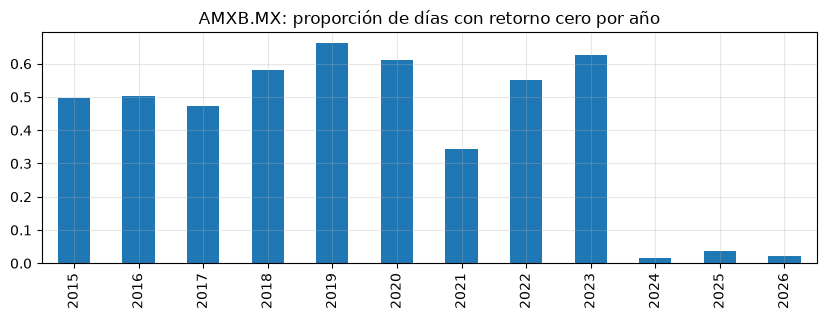

Correlación promedio de AMXB.MX con las demás emisoras: 0.10
Correlación promedio entre el resto de las emisoras: 0.22


In [5]:
# % de días con retorno exactamente cero: señal de precios repetidos o de poca operación
zero_share = (stock_rets == 0).mean().sort_values(ascending=False)
display(zero_share.head(5).to_frame("días con retorno cero").style.format("{:.1%}"))

worst = zero_share.index[0]
(stock_rets[worst] == 0).groupby(stock_rets.index.year).mean().plot.bar(figsize=(10, 3))
plt.title(f"{worst}: proporción de días con retorno cero por año")
plt.xlabel("")
plt.show()

# Efecto de los precios repetidos sobre la correlación
c = stock_rets.corr()
others = c.drop(index=worst, columns=worst)
print(f"Correlación promedio de {worst} con las demás emisoras: {c[worst].drop(worst).mean():.2f}")
print(f"Correlación promedio entre el resto de las emisoras: {others.values[~np.eye(len(others), dtype=bool)].mean():.2f}")

1. AMXB tiene retorno exactamente cero en el 41% de los días. Por año va de 34% a 66% hasta 2023 y baja a 2–4% desde 2024. América Móvil es de las emisoras más operadas de la BMV, así que esto apunta a un problema del histórico de Yahoo Finance y no de la acción.
2. Los precios repetidos desincronizan a AMXB del resto: su correlación con las demás emisoras sale artificialmente baja (0.10 en promedio, contra 0.22 entre el resto) y su curtosis sale inflada. Un optimizador de mínima varianza la sobreponderaría por una diversificación que no es real.
3. GCC (9.9%) y SIGMAFA (4.6%) también tienen días sin movimiento, en mucha menor medida. El resto está por debajo de 2.5%.
4. AMXB queda excluida para futuro análisis: se agregó a `EXCLUDED` en `src/config.py` y `clean_prices` la descarta por defecto, así que la exclusión aplica igual en todos los bloques.

In [6]:
# Exclusión por calidad de datos: la lista vive en src/config.py y clean_prices la aplica por defecto
print("Excluidas:", config.EXCLUDED)
prices = data.clean_prices(prices_raw)
log_rets = data.compute_returns(prices, log=True)
simple_rets = data.compute_returns(prices, log=False)
stock_rets, bench_rets = data.split_benchmark(log_rets)
print(f"Universo final: {stock_rets.shape[1]} emisoras | {stock_rets.shape[0]} retornos diarios | "
      f"{stock_rets.index.min().date()} → {stock_rets.index.max().date()}")

Excluidas: ['AMXB.MX']
Universo final: 31 emisoras | 2824 retornos diarios | 2015-07-20 → 2026-10-08


In [7]:
# Movimientos diarios más extremos del panel (en retorno simple)
moves = np.expm1(stock_rets).stack()
extremes = moves.loc[moves.abs().sort_values(ascending=False).index[:15]].rename("Retorno diario").reset_index()
extremes["Date"] = extremes["Date"].dt.date
extremes.style.format({"Retorno diario": "{:.1%}"}).hide(axis="index")

Date,Ticker,Retorno diario
2020-03-17,ALSEA.MX,-30.7%
2017-01-25,GCC.MX,30.4%
2020-03-17,VOLARA.MX,-28.8%
2020-08-03,SIGMAFA.MX,27.6%
2023-10-05,OMAB.MX,-26.2%
2020-11-09,GENTERA.MX,26.1%
2023-12-14,ASURB.MX,25.4%
2025-03-31,SIGMAFA.MX,-25.0%
2022-09-12,PE&OLES.MX,23.7%
2020-03-18,ALSEA.MX,-22.8%


1. Los movimientos de marzo de 2020 (ALSEA −30.7% y VOLARA −28.8% el 17 de marzo) corresponden al desplome por COVID-19, y los de OMA y GAP del 5 de octubre de 2023 al cambio en las bases de regulación tarifaria de los aeropuertos. Son movimientos reales del mercado.
2. SIGMAFA (antes Alfa) aparece cuatro veces. Dos de sus caídas coinciden con escisiones: −20.5% el 14 de diciembre de 2020, día en que Controladora Nemak empezó a cotizar por separado, y −25.0% el 31 de marzo de 2025, primer día hábil después de que Alfa anunció que concluyó la escisión de Alpek. En una escisión el accionista recibe acciones de la nueva empresa, así que esa caída no es una pérdida real, y Yahoo Finance no la ajusta. Por eso el retorno de SIGMAFA probablemente está subestimado.
3. Estos saltos se dejan en los datos, pero afectan la curtosis, el VaR y el drawdown de la emisora y hay que tenerlos presentes al interpretar sus resultados.

## 4. Rendimiento y riesgo por emisora

In [8]:
stock_simple, bench_simple = data.split_benchmark(simple_rets)

table = pd.DataFrame({t: metrics.summary(stock_simple[t]) for t in stock_simple.columns}).T
if bench_simple is not None:
    table.loc["NAFTRAC (benchmark)"] = metrics.summary(bench_simple)
# Índice de precios (sin dividendos), solo como referencia
table.loc["IPC de precios (^MXX)"] = metrics.summary(simple_rets[config.PRICE_INDEX])
table.sort_values("Sharpe", ascending=False).style.format(
    {"Retorno anual": "{:.1%}", "Volatilidad anual": "{:.1%}", "Sharpe": "{:.2f}",
     "Sortino": "{:.2f}", "Max drawdown": "{:.1%}"}
)

,Retorno anual,Volatilidad anual,Sharpe,Sortino,Max drawdown
Q.MX,20.2%,30.4%,0.76,0.78,-40.5%
GMEXICOB.MX,20.7%,34.5%,0.72,0.74,-46.5%
GCC.MX,14.0%,27.9%,0.61,0.65,-51.5%
GAPB.MX,14.7%,32.9%,0.58,0.57,-55.5%
OMAB.MX,13.8%,33.1%,0.56,0.56,-58.7%
AC.MX,10.2%,22.1%,0.55,0.58,-33.0%
GFNORTEO.MX,13.4%,32.7%,0.55,0.54,-54.3%
VESTA.MX,9.8%,24.8%,0.50,0.53,-32.9%
PE&OLES.MX,12.7%,44.7%,0.49,0.51,-71.8%
ASURB.MX,8.8%,29.4%,0.43,0.45,-47.6%


1. Retorno anual: El retorno compuesto de la muestra de años varía mucho entre emisoras. Va desde 20.7% a -5.4%.
2. Volatilidad anual: Es la volatilidad diaria de cada emisora multiplicada por la raíz de 252. 
3. Ratio de Sharpe: Dice qué tanto beneficio adicional se obtuvo por cada unidad de riesgo (considera la volatilidad al alza y a la baja). Entre mayor, mejor el activo. El Sharpe considera una tasa libre de riesgo como 0. 
4. Ratio de Sortino: Igualmente calcula qué tanto beneficio se obtiene del riesgo, pero en este caso solo penaliza la volatilidad negativa. 
5. Max drawdown: Es el punto más bajo desde el punto más alto al que llegó el activo. 

Lectura de la tabla:
1. El NAFTRAC tiene la menor volatilidad de toda la tabla (15.8%, contra 22% a 45% de las emisoras individuales). Es el efecto de la diversificación: el ETF replica al IPC, que combina los movimientos de 35 emisoras.
2. El benchmark es el NAFTRAC y no el índice `^MXX`, porque `^MXX` es un índice de precios que no incluye dividendos, mientras que los precios ajustados de las emisoras y del NAFTRAC sí los incluyen. En la misma ventana el NAFTRAC rinde 5.6% anual y `^MXX` 3.3%: comparar contra el índice de precios le daría una ventaja de más de 2 puntos por año a cualquier portafolio.
3. 10 de las 31 emisoras superan al NAFTRAC en Sharpe y 16 en retorno anual. Aun así la comparación favorece a las emisoras, porque el universo es la muestra actual del IPC, que contiene a las que sobrevivieron y crecieron (sesgo de supervivencia).
4. El riesgo individual es mucho mayor que el del benchmark: GENTERA, VOLARA, SIGMAFA y ALSEA perdieron más de 80% desde su máximo, contra −32.4% del NAFTRAC.
5. El retorno anual y el Sharpe no siempre cuentan la misma historia: Liverpool tiene retorno anual de −3.7% y Sharpe de 0.00. El Sharpe usa el promedio aritmético de los retornos diarios (≈0% anual en Liverpool), mientras que el retorno anual es compuesto. La diferencia es aproximadamente σ²/2 (27.2%² / 2 ≈ 3.7%): la volatilidad por sí sola reduce el retorno compuesto.

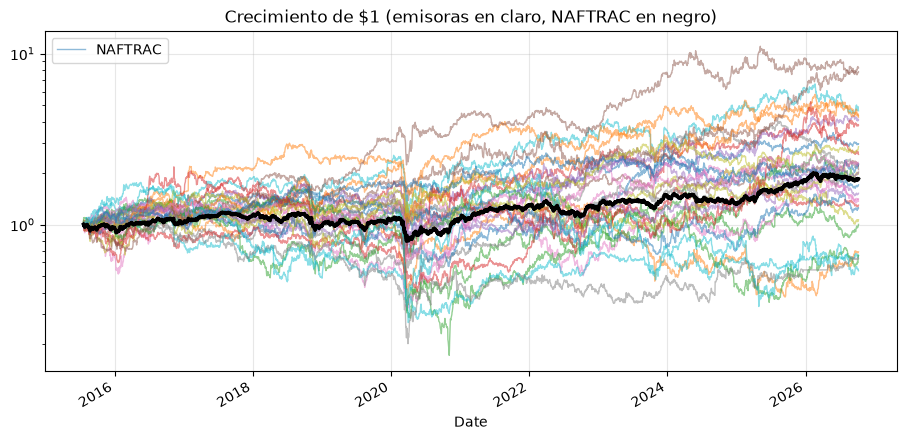

In [9]:
# Crecimiento de $1 invertido (base 1)
wealth = (1 + stock_simple).cumprod()
ax = wealth.plot(legend=False, alpha=0.5, lw=1, figsize=(11, 5))
if bench_simple is not None:
    (1 + bench_simple).cumprod().plot(ax=ax, color="black", lw=2.5, label="NAFTRAC")
    ax.legend(["NAFTRAC"])
ax.set_title("Crecimiento de $1 (emisoras en claro, NAFTRAC en negro)")
ax.set_yscale("log")
plt.show()

1. La dispersión entre emisoras es muy amplia: $1 invertido en julio de 2015 terminó entre $0.54 (VOLARA) y $8.23 (GMEXICO). La mediana de las emisoras es $2.02 y el NAFTRAC terminó en $1.85.
2. Cinco emisoras terminaron por debajo de $1 (VOLARA, SIGMAFA, Liverpool, ORBIA y ALPEK) y ALSEA quedó prácticamente en $1 después de más de 11 años.
3. La caída de marzo de 2020 se ve en casi todas las series al mismo tiempo: en una crisis las emisoras se mueven juntas.
4. La escala es logarítmica: distancias verticales iguales representan cambios porcentuales iguales.

## 5. Correlaciones

Las correlaciones altas entre emisoras limitan los beneficios de diversificación y son la base del clustering de HRP.

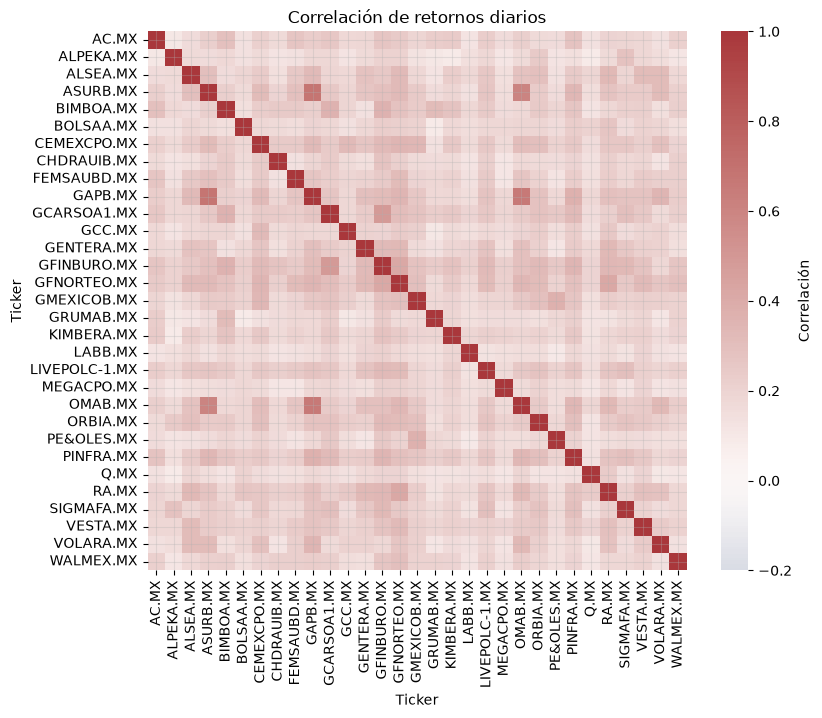

Correlación promedio entre pares: 0.22


In [10]:
corr = stock_rets.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-0.2, vmax=1, square=True,
            cbar_kws={"label": "Correlación"}, xticklabels=True, yticklabels=True)
plt.title("Correlación de retornos diarios")
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print(f"Correlación promedio entre pares: {upper.mean():.2f}")

La correlación promedio es de 0.22, esto implica que hay correlación entre activos pero no es muy alta.
1. Hay algunas correlaciones que sí están en el rango de 0.4-0.6, esto implica una correlación media y considerable más adelante. Surge principalmente de empresas del mismo sector. 
2. Las correlaciones bajas son positivas porque permiten que la diversificación minimice el riesgo y mantenga el retorno potencial. 

Volatilidad anual promedio por emisora: 31.3%
Volatilidad anual del portafolio igual ponderado: 15.4%

Pares con correlación > 0.4: 6 de 465 | mínima: 0.09
Pares más correlacionados:
Ticker       Ticker     
ASURB.MX     GAPB.MX        0.68
GAPB.MX      OMAB.MX        0.66
ASURB.MX     OMAB.MX        0.60
GCARSOA1.MX  GFINBURO.MX    0.49
GFNORTEO.MX  RA.MX          0.42
GFINBURO.MX  GFNORTEO.MX    0.42


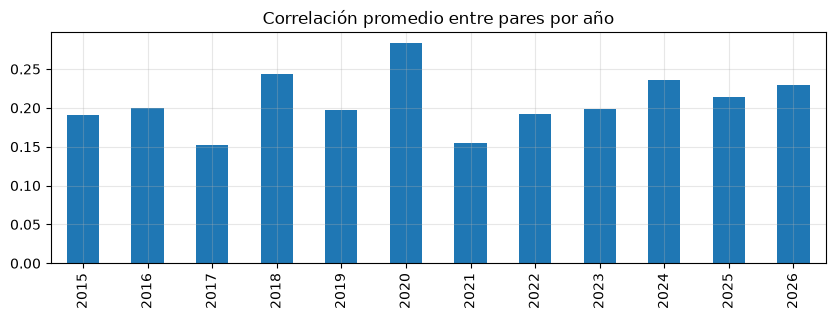

Correlación promedio del 20-feb al 30-abr de 2020: 0.35


In [11]:
# ¿Cuánto riesgo elimina la diversificación? Emisora promedio vs. portafolio igual ponderado
# (rebalanceo diario y sin costos; solo como referencia descriptiva)
ew = stock_simple.mean(axis=1)
print(f"Volatilidad anual promedio por emisora: {stock_simple.apply(metrics.annualized_volatility).mean():.1%}")
print(f"Volatilidad anual del portafolio igual ponderado: {metrics.annualized_volatility(ew):.1%}")

print(f"\nPares con correlación > 0.4: {(upper > 0.4).sum()} de {upper.notna().sum()} | mínima: {upper.min():.2f}")
print("Pares más correlacionados:")
print(upper.sort_values(ascending=False).head(6).round(2).to_string())

# La correlación no es constante: promedio entre pares por año
def avg_corr(rets):
    c = rets.corr()
    return c.where(np.triu(np.ones(c.shape), k=1).astype(bool)).stack().mean()

stock_rets.groupby(stock_rets.index.year).apply(avg_corr).plot.bar(figsize=(10, 3))
plt.title("Correlación promedio entre pares por año")
plt.xlabel("")
plt.show()
print(f"Correlación promedio del 20-feb al 30-abr de 2020: {avg_corr(stock_rets.loc['2020-02-20':'2020-04-30']):.2f}")

Qué implica para la diversificación:
1. La diversificación sí funciona: la emisora promedio tiene una volatilidad anual de 31.3% y un portafolio igual ponderado de las 31, de 15.4%. Cerca de la mitad del riesgo individual se elimina al combinar.
2. Pero tiene un piso: todas las correlaciones son positivas (la mínima es 0.09), así que hay un riesgo común de mercado que no se elimina agregando más emisoras. El 15.4% del portafolio queda muy cerca del 15.8% del NAFTRAC.
3. Las correlaciones altas se concentran en grupos: los tres grupos aeroportuarios (ASUR, GAP y OMA, entre 0.60 y 0.68) y emisoras del mismo sector o grupo (Carso–Inbursa 0.49, Banorte–Regional 0.42, Inbursa–Banorte 0.42). Solo 6 de los 465 pares superan 0.4. Estos grupos son los que debería encontrar el clustering de HRP.
4. La correlación no es constante: por año va de 0.15 a 0.28, y entre el 20 de febrero y el 30 de abril de 2020 sube a 0.35. La diversificación se reduce justo cuando más se necesita.

## 6. Hechos estilizados

### 6.1 Colas pesadas
Si los retornos fueran normales, la curtosis en exceso sería ≈ 0 y el QQ-plot caería sobre la diagonal.

In [12]:
stats_tbl = pd.DataFrame({
    "Asimetría": stock_rets.skew(),
    "Curtosis en exceso": stock_rets.kurt(),
    "Jarque-Bera p-value": [stats.jarque_bera(stock_rets[c].dropna())[1] for c in stock_rets.columns],
})
display(stats_tbl.style.format({"Asimetría": "{:.2f}", "Curtosis en exceso": "{:.1f}", "Jarque-Bera p-value": "{:.2e}"}))

,Asimetría,Curtosis en exceso,Jarque-Bera p-value
Ticker,,,
AC.MX,0.20,1.9,7.26e-94
ALPEKA.MX,-0.26,7.0,0.00e+00
ALSEA.MX,-2.35,43.2,0.00e+00
ASURB.MX,0.37,14.8,0.00e+00
BIMBOA.MX,0.27,3.7,0.00e+00
BOLSAA.MX,0.39,8.5,0.00e+00
CEMEXCPO.MX,0.27,2.3,6.27e-143
CHDRAUIB.MX,0.23,2.0,2.28e-112
FEMSAUBD.MX,0.17,5.7,0.00e+00


1. La asimetría muestra hacia dónde están cargados los casos extremos. Con un valor negativo están cargados a la izquierda, con uno positivo a la derecha y con uno muy cercano a 0 no hay un lado predominante. En este caso, hay una distribución de las 3 situaciones. 
2. La curtosis en exceso muestra qué tan susceptibles son los activos a los eventos extremos, un valor mayor a 0 cuenta como "positivo". En este caso, todos los activos son mayores a 0, los valores más altos son los de mayor movimiento por lo que son los de mayor riesgo. 
3. El Jarque-Bera p-value muestra qué tan probable es que el comportamiento se asemeje a la curva normal, entre más bajo el valor, menos se asemeja a la distribución normal. En este caso, se rechaza normalidad en las 31 emisoras.

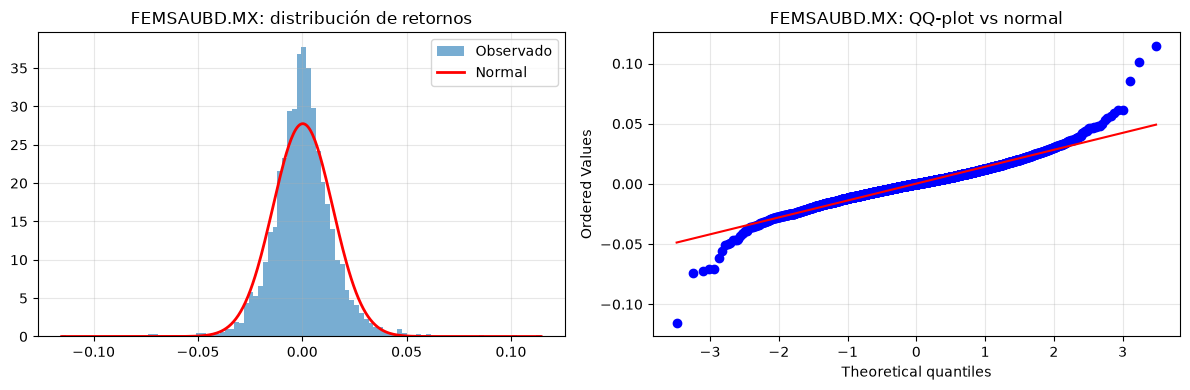

In [13]:
ticker = "FEMSAUBD.MX"   # cambia por la emisora que quieras inspeccionar
r = stock_rets[ticker].dropna()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(r, bins=100, density=True, alpha=0.6, label="Observado")
x = np.linspace(r.min(), r.max(), 400)
axes[0].plot(x, stats.norm.pdf(x, r.mean(), r.std()), "r", lw=2, label="Normal")
axes[0].set_title(f"{ticker}: distribución de retornos"); axes[0].legend()
stats.probplot(r, dist="norm", plot=axes[1])
axes[1].set_title(f"{ticker}: QQ-plot vs normal")
plt.tight_layout(); plt.show()

1. En la distribución de la izquierda podemos notar un exceso considerable en los valores medios, un hueco a 1-2 desviaciones estándar del centro y excepciones en los extremos.
2. En la gráfica de la derecha, podemos ver cómo se forma un estilo de S con los activos, lo que confirma la teoría de las colas pesadas en los activos. 

### 6.2 Agrupamiento de volatilidad
Los retornos casi no tienen autocorrelación, pero **sus cuadrados sí**: la volatilidad alta tiende a seguir a la volatilidad alta.
Esto es lo que modelan GARCH y los pronósticos de volatilidad del Bloque 4.

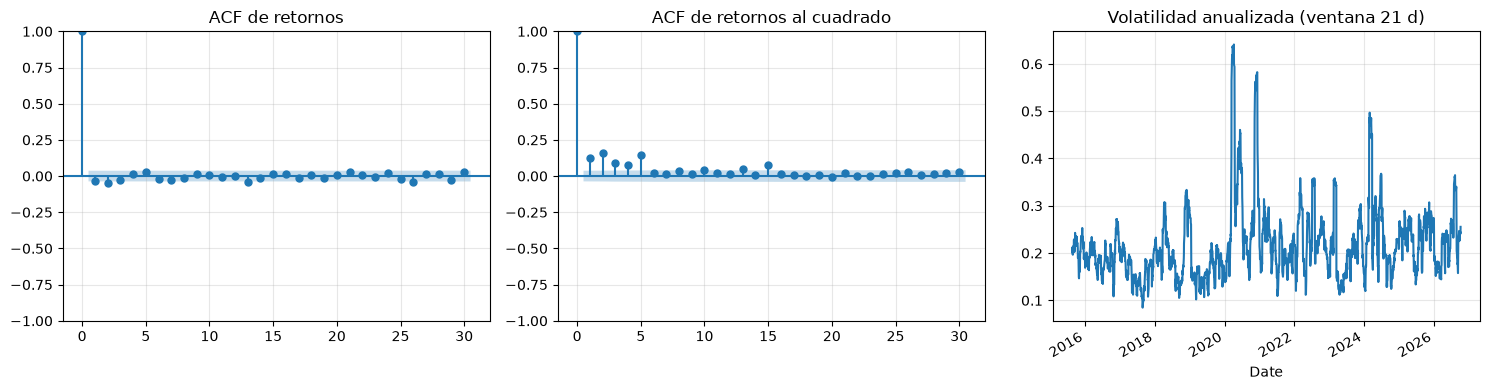

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
plot_acf(r, lags=30, ax=axes[0]); axes[0].set_title("ACF de retornos")
plot_acf(r**2, lags=30, ax=axes[1]); axes[1].set_title("ACF de retornos al cuadrado")
r.rolling(21).std().mul(np.sqrt(config.TRADING_DAYS)).plot(ax=axes[2])
axes[2].set_title("Volatilidad anualizada (ventana 21 d)")
plt.tight_layout(); plt.show()

1. La función de autocorrelación no tiene impacto directo de forma constante en el retorno futuro, se pierde la información en ruido. El retorno actual no impacta al retorno futuro. 
2. En cuanto a la función de autocorrelación al cuadrado, en este caso los cuadrados sí tienen efecto en la volatilidad futura. Volatilidad alta de hoy implica una gran probabilidad de volatilidad alta en el futuro, sin importar el signo. 
3. La volatilidad anualizada en los activos muestra picos constantes y no muestra ninguna tendencia clara en este primer análisis. 

## 7. Conclusiones del Bloque 1

- ¿Qué emisoras se descartaron y por qué?  
Se descartaron Coca-Cola FEMSA, BanBajío y La Comer por falta de historial de activos. Las tres acciones no cuentan con 95% o más de datos desde 2015 por lo que se descartaron para este proyecto. No tienen datos erróneos: empezaron a cotizar después (2016, 2017 y 2019).  
La ventana efectiva empieza el 17 de julio de 2015 y no en enero, porque es cuando empieza a cotizar Quálitas y se exigen datos completos para todas las emisoras.  
También se excluyó América Móvil (AMXB) por calidad de datos: tiene retorno exactamente cero en el 41% de los días (sección 3.1). El universo final es de 31 emisoras.
- ¿Qué tan grandes son las colas respecto a la normal? ¿Qué implica para el VaR paramétrico?  
Las colas son bastante grandes respecto a la normal, esto se ve reflejado en la curtosis que en todos los activos es bastante superior a 1. Además, en el gráfico de la distribución normal contra los datos históricos es normal ver picos sobre la línea roja en los extremos.  
Esto implica que los días extremos son comunes y el VaR paramétrico pierde efectividad al no ser similar a una distribución normal. Al tener extremos frecuentes, qué tanto va después del umbral se vuelve muy importante y es necesario emparejar el VaR con el CVaR. El VaR al 99% subestima mientras que al 95% sobreestima. 
- ¿Cómo se ve el agrupamiento de volatilidad? ¿Qué pasó en marzo de 2020?  
El agrupamiento de volatilidad presenta picos y valles a lo largo de los años que suben mucho en los picos y regresan a un valor ~20%.  
Después de analizar un poco más a detalle, es común ver un pico muy alto de volatilidad en distintos activos en marzo de 2020, relacionado con la pandemia de COVID-19.
- ¿Qué tan correlacionadas están las emisoras? ¿Qué implica para la diversificación?  
La gran mayoría de emisoras muestran una correlación baja entre sí, promediando una correlación de 0.22. Hay algunos casos en los que la relación es considerable en el rango de 0.4-0.6 pero no son muy constantes. En cambio, muchas de las correlaciones están en el rango de 0-0.2 implicando una correlación baja entre sí.  
Para la diversificación implica que sí se reduce el riesgo, pero con un piso: el portafolio igual ponderado tiene 15.4% de volatilidad anual contra 31.3% de la emisora promedio, y como todas las correlaciones son positivas queda un riesgo de mercado que no se elimina agregando emisoras. Además, la correlación promedio sube a 0.35 en el desplome de 2020 (0.20 en 2019): la diversificación se reduce justo cuando más se necesita.
- Limitaciones identificadas (sesgo de supervivencia, calidad de datos).  
Hay ciertas limitaciones que se identificaron, la primera es el sesgo de supervivencia. En este caso, se están utilizando las empresas que siguen/ingresaron al top 35 de la BMV, aunque se hace el estudio de 2015, hay cierta rotación durante estos 10 años.  
La calidad de datos es relativamente buena, casi todas las emisoras tienen el 100% de datos. El riesgo principal en este caso es que Yahoo Finance no tenga la información histórica correcta.  
Sin embargo, tener datos completos no garantiza que sean correctos. Se identificaron tres problemas (secciones 2, 3.1 y 4): (1) AMXB tiene retorno exactamente cero en el 41% de los días, casi todos antes de 2024, lo que distorsiona su correlación y su curtosis, por lo que se excluyó del universo; (2) SIGMAFA tiene caídas de −20.5% y −25.0% que coinciden con las escisiones de Nemak y Alpek y que Yahoo Finance no ajusta; (3) el índice `^MXX` es de precios y no incluye dividendos, mientras que los precios de las emisoras sí, por lo que se usa como benchmark el ETF NAFTRAC con precio ajustado; en Yahoo Finance a este ETF le faltan unos 7 días por año, que se rellenan con el precio anterior.